In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## style and bar
plt.style.use("ggplot")
color_bar = sns.color_palette()

In [2]:
path = "/content/drive/MyDrive/ml project/dataset/Dry_Bean_Dataset.xlsx"
df = pd.read_excel(path)
df.shape

(13611, 17)

In [3]:
df.head(1)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER


### 1. Data Preprocessing & Exploration
We will inspect the dataset for any missing values and look at basic statistics.

In [4]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Display basic statistics
display(df.describe())

Missing values per column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [7]:
print("It's cleaned dataset !!")

It's cleaned dataset !!


### 2. Data Visualization
Let's visualize the target variable distribution (`Class`) and a correlation heatmap of all continuous features.

/tmp/ipykernel_1843/3295575990.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Class', order=df['Class'].value_counts().index, palette='viridis')


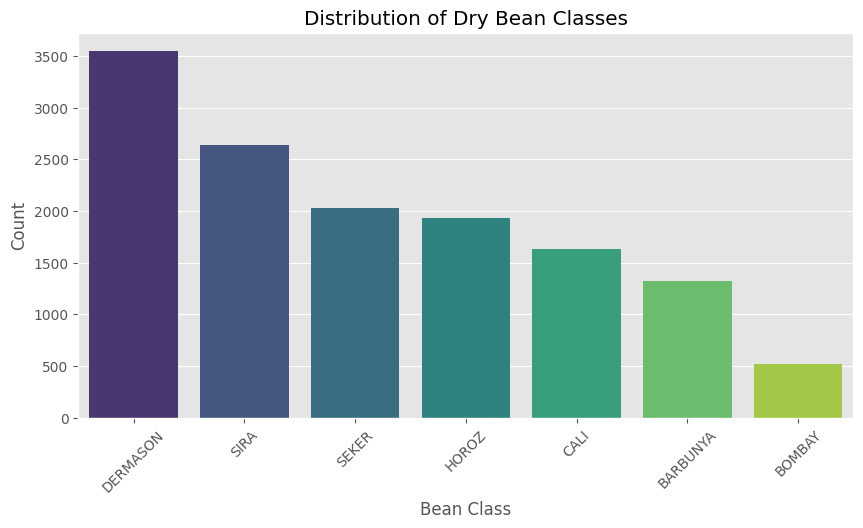

In [5]:
# Plotting the target Class distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Class', order=df['Class'].value_counts().index, palette='viridis')
plt.title('Distribution of Dry Bean Classes')
plt.xlabel('Bean Class')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

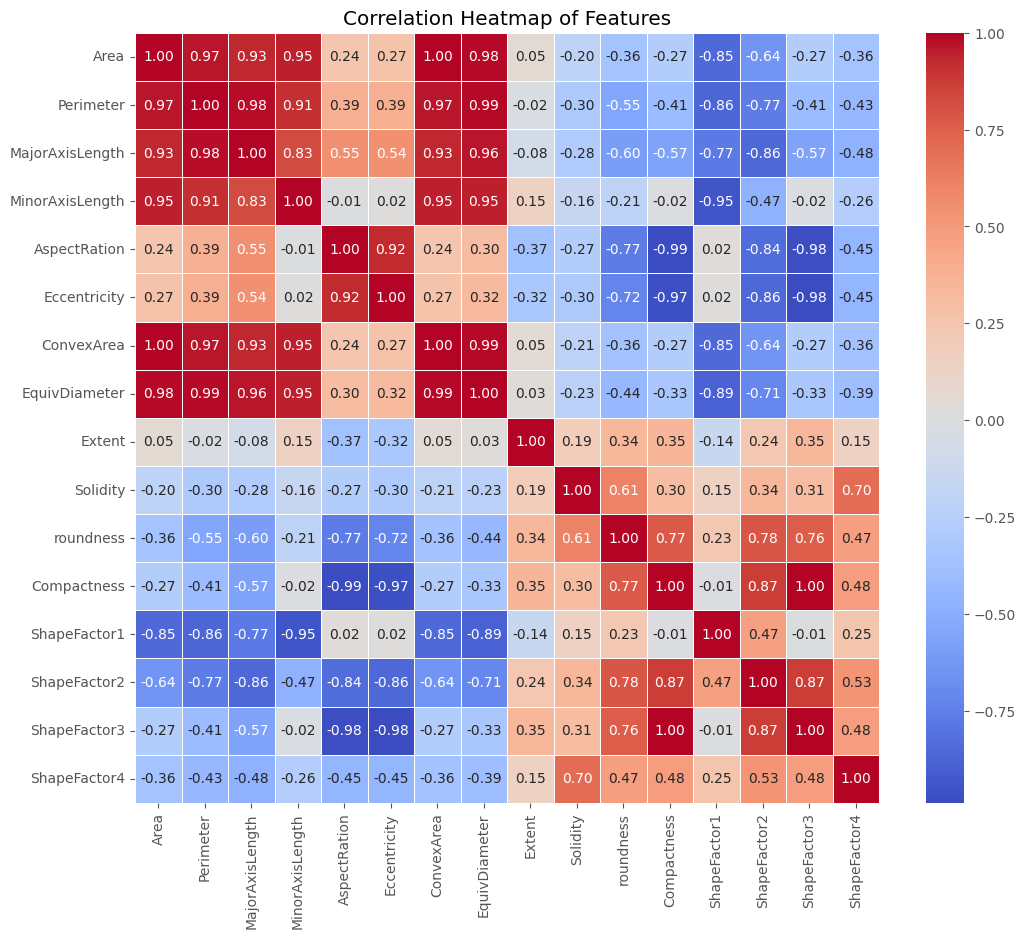

In [6]:
# Correlation Heatmap for continuous features
plt.figure(figsize=(12, 10))
corr_matrix = df.drop(columns=['Class']).corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

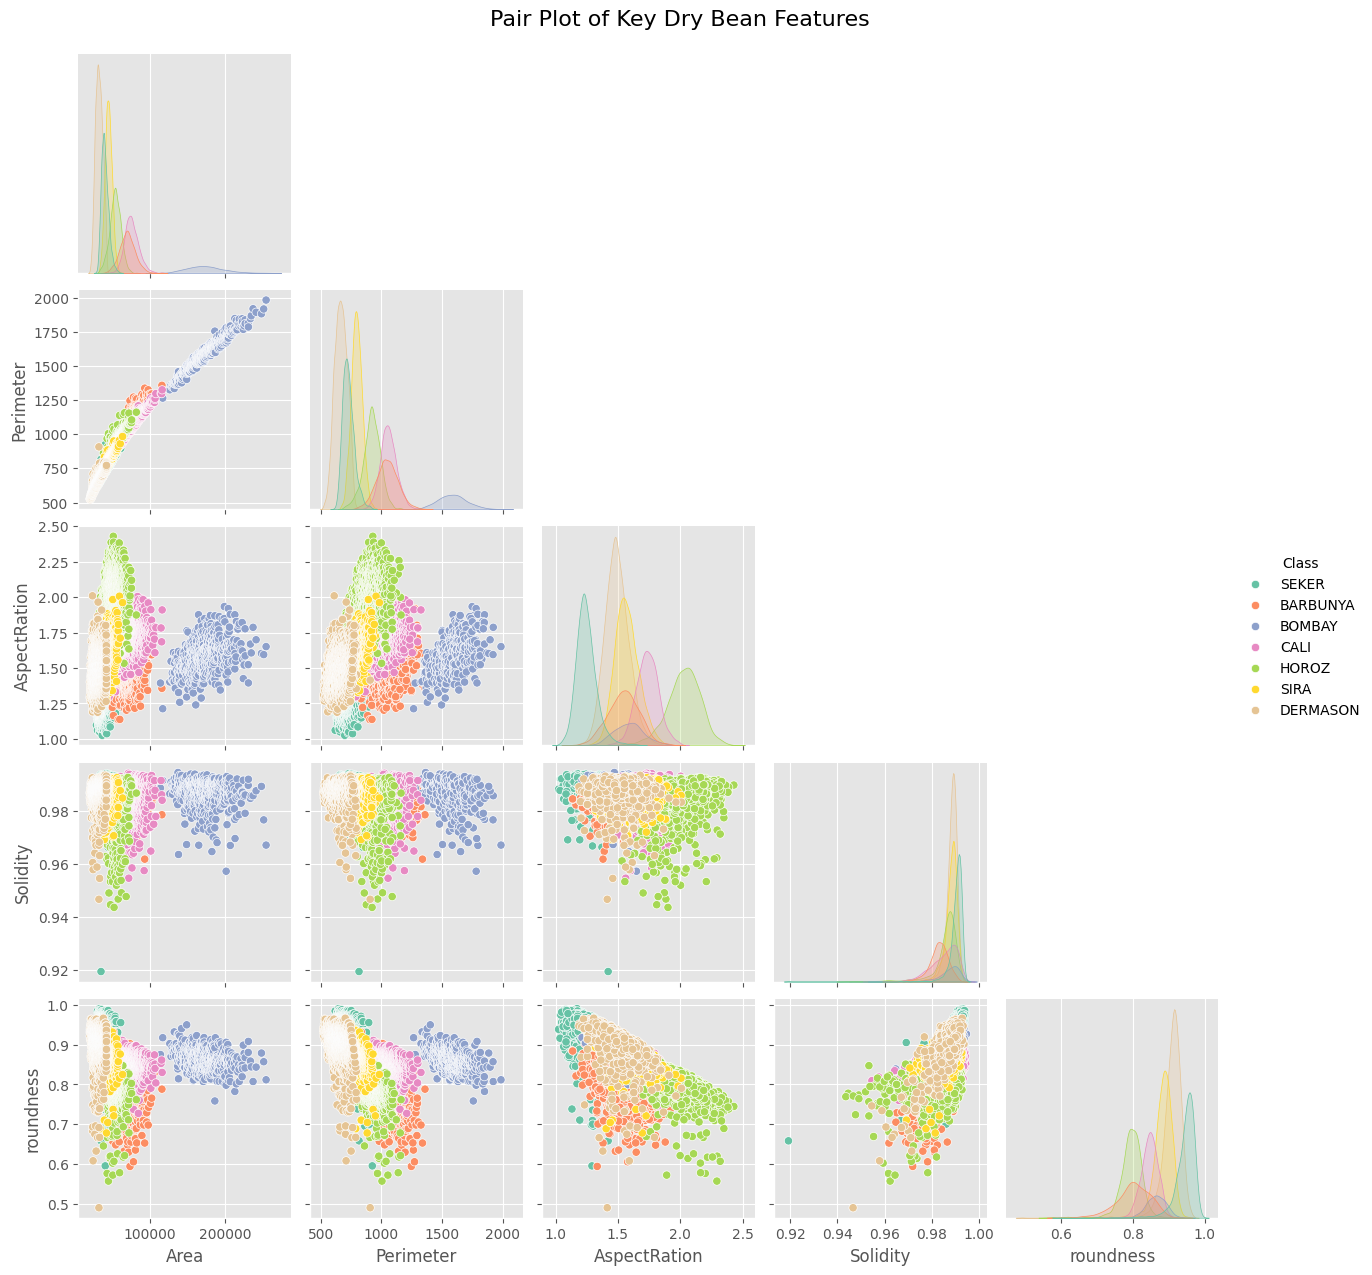

In [11]:
# Selecting a subset of key shape and dimension features for a clear pair plot
key_features = ['Area', 'Perimeter', 'AspectRation', 'Solidity', 'roundness', 'Class']

# Draw the pair plot colored by the bean Class
sns.pairplot(df[key_features], hue='Class', palette='Set2', corner=True)
plt.suptitle('Pair Plot of Key Dry Bean Features', y=1.02, fontsize=16)
plt.show()

### 3. Outlier Detection across All Features
We will visualize the distribution of all 16 continuous attributes using boxplots to identify potential outliers across the dataset.

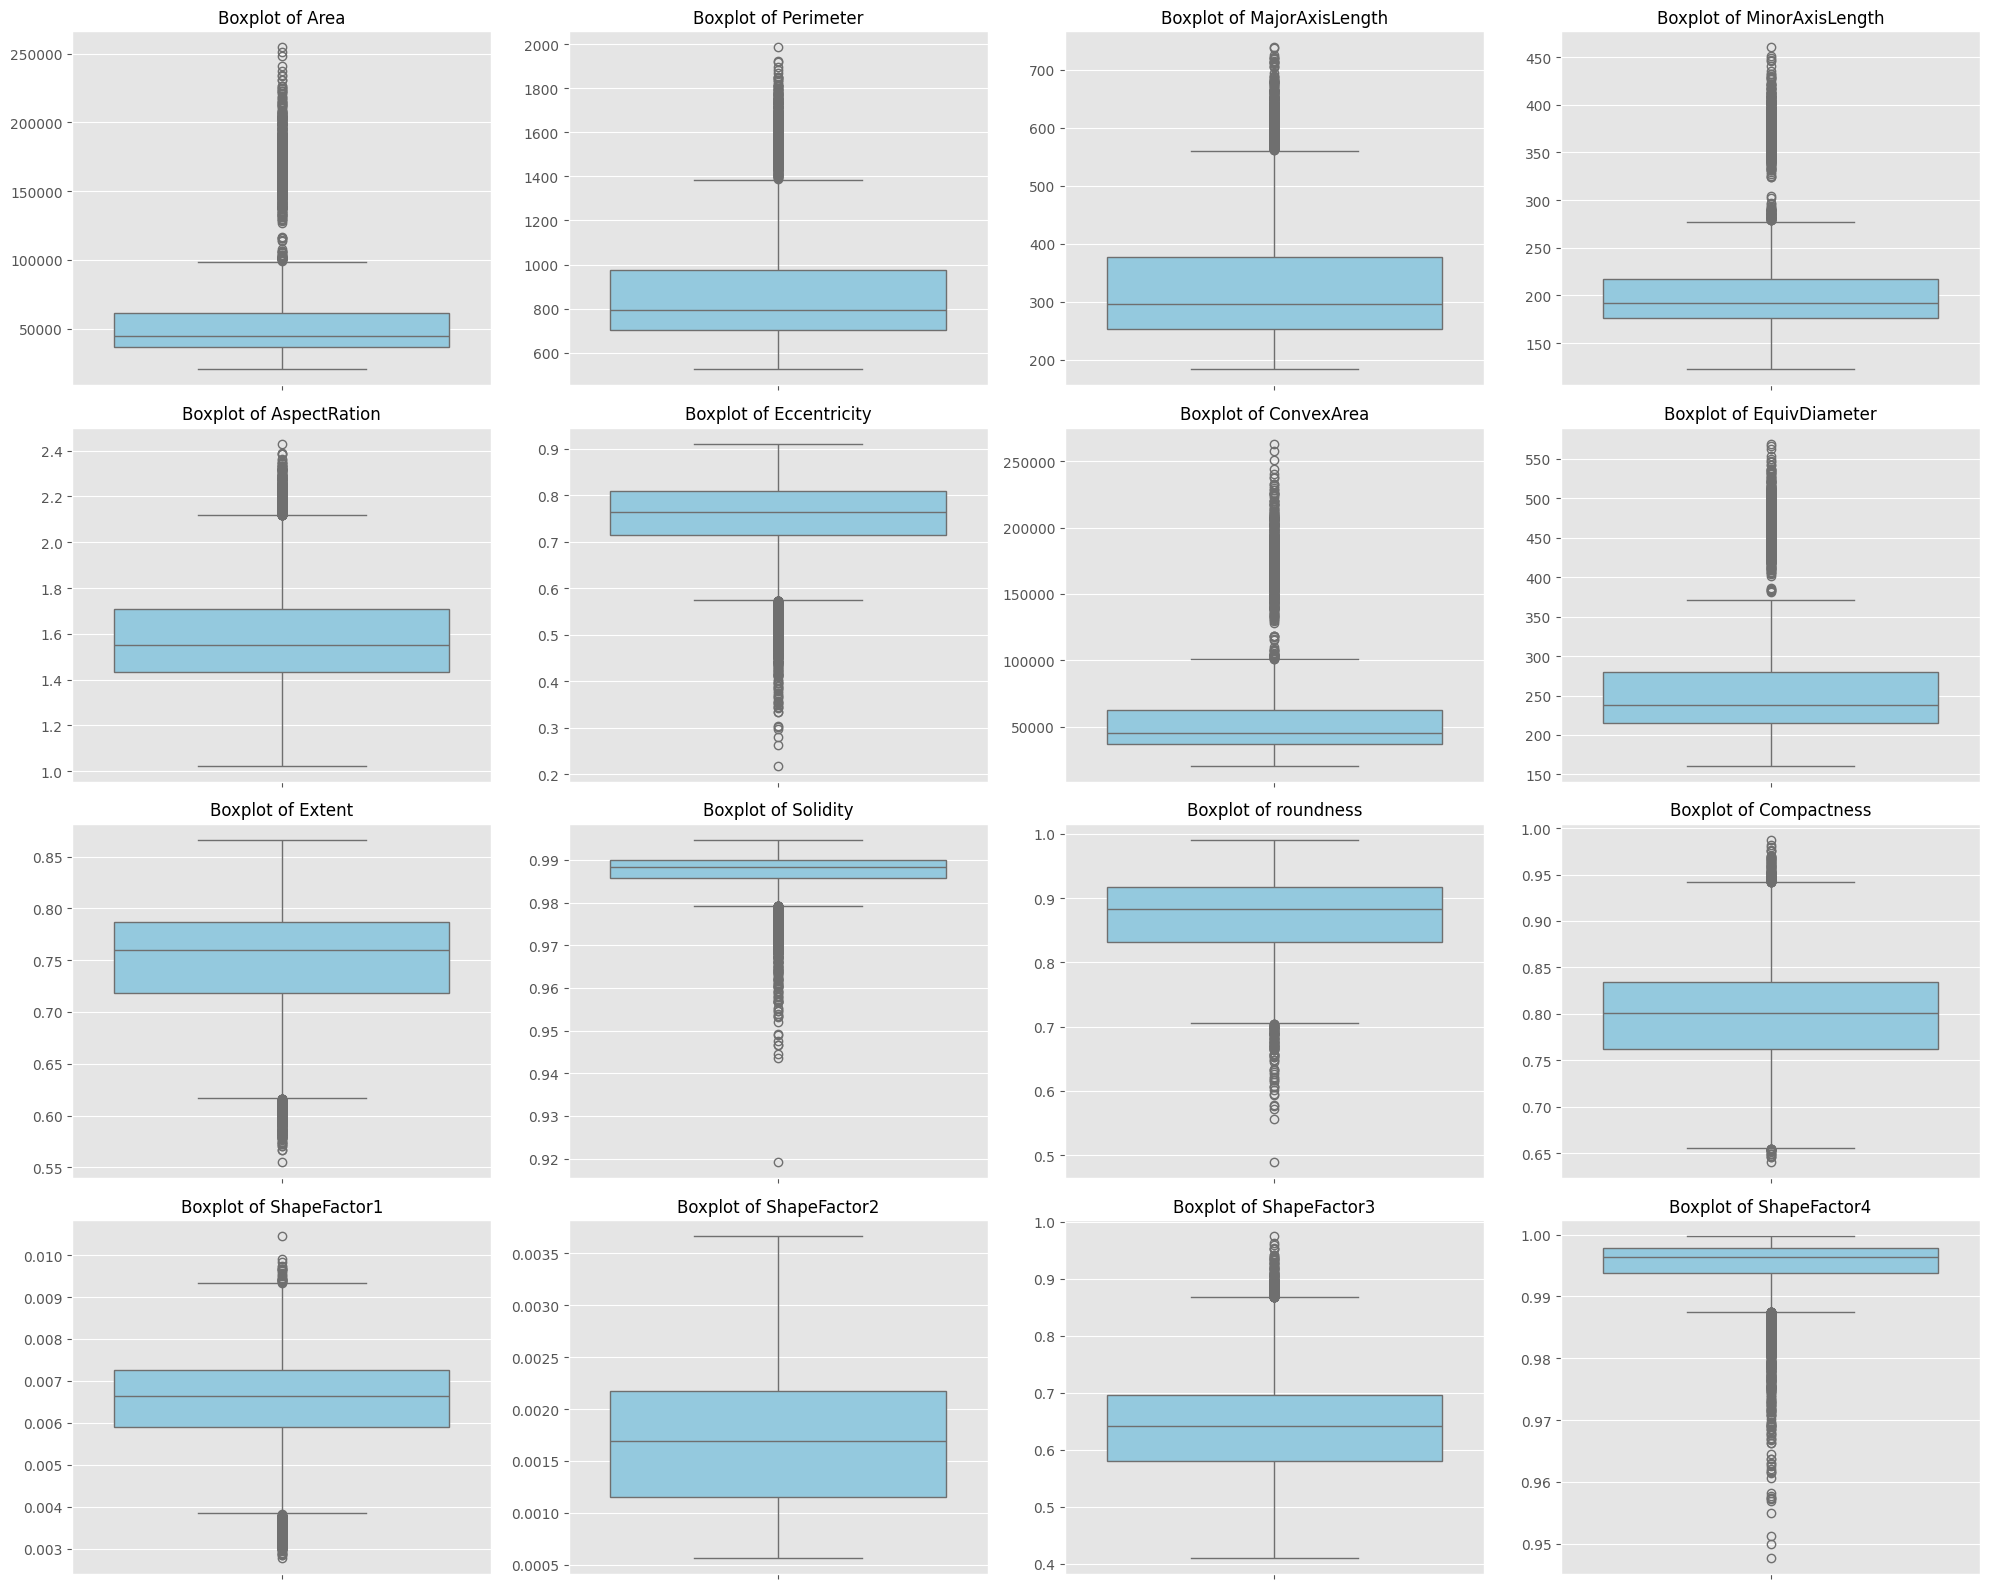

In [12]:
# Identify all numeric features (excluding the 'Class' column)
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Set up the matplotlib figure grid (4 rows by 4 columns to fit 16 features)
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()
### this outlier we can ignore as different climatic conditions may affect it !!